> **Historical analysis:** this notebook retains the earlier temporal-spread response and outputs. For the current lag / plateau-duration / peak-excess metrics, start with [the results synthesis](synthetic_results_synthesis.ipynb) and [predictor validation](synthetic_predictor_validation.ipynb). Earlier `event_duration_change_pct` values here denote cumulative-volume t01–t99, not the current plateau duration.

# Full-grid factor effects and interactions

**Question:** which geometric controls change the collapse response, how do those controls interact, and does the resistance predictor respond to the same controls?

This analysis uses all 2,187 equally weighted configurations for each of seven parent–child comparisons. It reads completed results and writes only analysis outputs. It does not rerun routing or modify the experimental design.

The compact overview comprises main/total sensitivity, all 21 pairwise interactions, matched factor changes, and a resistance comparison. Detailed plots show selected interactions rather than repeating seven-panel baseline slices.

Results describe this discrete grid and its parameter ranges. They are deterministic model sensitivity, not statistical significance or hydraulic validation. See [the applicability audit](synthetic_hydraulic_applicability.ipynb) for the unresolved physical reference-state assumptions.

This version includes **nested/main_island_only**: collapse the main island while retaining the upper inner branch and its length adjustment. Results come from `full_grid_island`; the original six-comparison grid remains in `full_grid`.

Timing sensitivity is expressed only as **percentage lag change**. The predictor analysis uses the complete primary x-variable, including length fraction and exposure; absolute lag-change sensitivity is omitted.

**Three routing responses:** peak-lag change, event-volume temporal-spread change,
and peak-excess change, each relative to the parent. Shape metrics are derived
from saved complete hydrographs using the known background discharge. The
balanced grid is unchanged; the focused narrow-branch/shortening experiments
remain a separate illustration outside the factorial decomposition.


**Current synthetic version · 30 September 2026:** BASED reference depth, local width–depth exponent **α=0.65**, Manning n=0.035, X=0.1 and 200m segmentation/floor. Responses and local-kb resistance are recomputed from the versioned routing run. Geometry and validation partitions are unchanged. **Real-case comparison is deferred until the updated-slope runs.** Earlier outputs are preserved separately; the old-versus-new comparison changes the complete hydraulic setup, not alpha alone.


In [1]:
from pathlib import Path
from itertools import combinations, product
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'synthetic_experiments').is_dir())
import sys
sys.path.insert(0,str(ROOT/'synthetic_experiments/investigations'))
from analysis_paths import results_root
ACTIVE_RUN=results_root()/'full_grid_island'
ACTIVE_EXTENSION=results_root()/'embedded_width_length_extension'
assert json.loads((ACTIVE_RUN/'manifest.json').read_text())['config']['selected_hydraulic_reference']['depth_alpha']==.65
RUN=ACTIVE_RUN
OUT = RUN/'factor_analysis'
OUT.mkdir(parents=True, exist_ok=True)
data = pd.read_csv(RUN/'results.csv')
manifest = json.loads((RUN/'manifest.json').read_text())
FACTORS = ['total_width_m','reference_slope','outer_a_fraction','inner_fraction',
           'length_multiplier','total_length_m','internal_location']
LABELS = ['Width','Slope','Outer A fraction','Inner / crossover fraction',
          'Branch length multiplier','Network extent','Internal location']
LABEL = dict(zip(FACTORS,LABELS))
STATES = ['simple/full','nested/inner_only','nested/main_island_only','nested/full','crossover/upstream_only',
          'crossover/downstream_only','crossover/full']
NAMES = ['Simple: full','Nested: inner','Nested: main island','Nested: full','Crossover: upstream',
         'Crossover: downstream','Crossover: full']
NAME = dict(zip(STATES,NAMES))
LEVELS = {f: sorted(data[f].unique()) for f in FACTORS}
LEVELS['internal_location'] = ['upstream','central','downstream']
ROUTING_RESPONSES = {'lag_shift_pct':'Peak-lag change (%)',
    'event_duration_change_pct':'Event-duration change (%)',
    'peak_excess_change_pct':'Peak-excess change (%)'}
RESPONSES = {**ROUTING_RESPONSES,
             'resistance_predictor':r'$L_f E[-\log_{10}(\Lambda_K)]$'}
# Check that the analysed predictor is the complete primary x-variable.
expected_x = data.length_fraction * data.width_fraction * (-np.log10(data.Lambda_matched))
assert np.allclose(data.resistance_predictor, expected_x, rtol=1e-12, atol=1e-12)
assert set(data.child_state) == set(STATES)
for state, frame in data.groupby('child_state'):
    assert len(frame) == np.prod([len(LEVELS[f]) for f in FACTORS])
    assert not frame.duplicated(FACTORS).any()
assert np.isfinite(data[['lag_shift_pct','resistance_predictor']]).all().all()
pd.set_option('display.max_columns',20)
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print(f'{len(data):,} comparisons; {len(STATES)} collapse types; 21 factor pairs per response/type.')


15,309 comparisons; 7 collapse types; 21 factor pairs per response/type.


## Current event-shape definitions

The three primary responses are peak-lag change, plateau-to-plateau event-duration change, and peak-excess change. All changes are $100(y_c/y_p-1)$.

**Event duration** runs from the first departure from the initial plateau to final settlement at the terminal plateau. A shared absolute tolerance equal to 1% of the parent peak amplitude is used for both states, with at least one hour of settled tail. The 0.5% and 2% tolerance checks appear in the results synthesis. This is not a cumulative-volume duration.

**Peak excess** is maximum discharge above the initial 100 m³/s baseflow. Positive change means a higher excess peak. **Lag** is outlet peak time minus inlet peak time.

Temporal standard deviation and cumulative-volume t01–t99 duration remain secondary diagnostics in exported tables. Routing outputs have passed initialization, final-settling and excess-volume checks. This notebook reads the selected results without rerouting.

In [2]:
import sys
sys.path.insert(0,str(ROOT/'synthetic_experiments/investigations'))
from event_shape_metrics import volume_shape
# Plateau duration is already recomputed using the fixed 1% parent threshold.
data=pd.read_parquet(RUN/'current_analysis/current_comparisons.parquet')
assert np.isfinite(data[list(RESPONSES)]).all().all()
(OUT/'event_shape_cache.json').write_text(json.dumps(dict(source=str(RUN/'current_analysis/current_comparisons.parquet'),plan_id=manifest['plan_id'],primary_duration='1% parent-amplitude first departure to final settlement',temporal_spread='secondary diagnostic only'),indent=2))
display(data.groupby('child_state')[list(ROUTING_RESPONSES)].agg(['min','median','max']).round(2))

lag_shift_pct                \
                                    min median    max   
child_state                                             
crossover/downstream_only        -23.52 -12.03  -2.65   
crossover/full                   -26.76 -18.64 -10.26   
crossover/upstream_only          -24.71 -10.67  -0.93   
nested/full                      -27.33 -18.10  -8.96   
nested/inner_only                -20.23  -8.26  -2.16   
nested/main_island_only          -23.33 -10.00  -2.91   
simple/full                      -39.69 -23.68  -3.34   

                          event_duration_change_pct               \
                                                min median   max   
child_state                                                        
crossover/downstream_only                    -16.50  -0.61  6.99   
crossover/full                               -18.39  -2.01 -0.15   
crossover/upstream_only                      -16.00  -0.78  7.32   
nested/full                                  -19.74  -2.14 -0.13   
nested/inner_only                            -16.46  -0.13  7.23   
nested/main_island_only                      -17.82  -0.78  1.84   
simple/full                                  -19.90  -1.49 -0.08   

                          peak_excess_change_pct                
                                             min median    max  
child_state                                                     
crossover/downstream_only                  -4.24   0.82  16.27  
crossover/full                              0.31   2.12  22.74  
crossover/upstream_only                    -3.90   0.93  18.80  
nested/full                                 0.26   2.27  22.64  
nested/inner_only                          -5.06   0.38  11.60  
nested/main_island_only                    -1.69   1.00  10.44  
simple/full                                 0.16   1.72  19.20

## 1. Decompose variation across the grid

For each response and collapse type, average over all other factor settings to obtain a main effect $f_i(x_i)=E[Y|x_i]-E[Y]$. A pair interaction is the part left after subtracting both main effects:

$$f_{ij}(x_i,x_j)=E[Y|x_i,x_j]-E[Y]-f_i(x_i)-f_j(x_j).$$

Their mean squares are orthogonal variance components on this complete, equally weighted grid. Report each component as a percentage of total response variance. The remainder includes all effects involving three or more factors. No linearity or numerical spacing of the three levels is assumed.

**Total sensitivity** for a factor includes every interaction involving it, calculated as $E[\mathrm{Var}(Y|X_{-i})]/\mathrm{Var}(Y)$. Total sensitivities overlap and must not be summed. Main effects, distinct pair components, and the higher-order remainder do sum to 100%. No p-values are computed.

In [3]:
def decompose(frame, factors, response):
    y = frame[response].to_numpy(float)
    mean = y.mean()
    variance = np.mean((y-mean)**2)
    # Treat only machine-scale fluctuations around a constant as zero variance.
    if variance <= np.finfo(float).eps**2 * max(1.,np.mean(y*y)):
        return [], [], dict(variance=variance,main_share=0.,pair_share=0.,higher_share=0.,constant=True)
    main_terms, main_rows, pair_rows = {}, [], []
    for factor in factors:
        term = frame.groupby(factor,observed=True)[response].transform('mean').to_numpy()-mean
        main_terms[factor] = term
        rest = [f for f in factors if f != factor]
        conditional = frame.groupby(rest,observed=True)[response].transform('mean').to_numpy()
        first = np.mean(term**2)/variance
        total = np.mean((y-conditional)**2)/variance
        main_rows.append(dict(factor=factor,main_share=first,total_share=total))
    for a,b in combinations(factors,2):
        pair = frame.groupby([a,b],observed=True)[response].transform('mean').to_numpy()-mean-main_terms[a]-main_terms[b]
        pair_rows.append(dict(factor_a=a,factor_b=b,pair_share=np.mean(pair**2)/variance))
    main_sum = sum(r['main_share'] for r in main_rows)
    pair_sum = sum(r['pair_share'] for r in pair_rows)
    residual = y-mean-sum(main_terms.values())
    for a,b in combinations(factors,2):
        residual -= frame.groupby([a,b],observed=True)[response].transform('mean').to_numpy()-mean-main_terms[a]-main_terms[b]
    higher = np.mean(residual**2)/variance
    assert np.isclose(main_sum+pair_sum+higher,1,atol=1e-10)
    assert all(r['total_share']+1e-10>=r['main_share'] for r in main_rows)
    return main_rows,pair_rows,dict(variance=variance,main_share=main_sum,pair_share=pair_sum,higher_share=higher,constant=False)

# Independent check: centered additive and pure interaction components of known variance.
toy = pd.DataFrame(product([-1.,0.,1.],repeat=3),columns=['a','b','c'])
toy['y'] = 2*toy.a+3*toy.a*toy.b
m,p,s = decompose(toy,['a','b','c'],'y')
assert np.isclose(m[0]['main_share'],.4) and np.isclose(m[0]['total_share'],1)
assert np.isclose(p[0]['pair_share'],.6) and np.isclose(s['higher_share'],0)
main_rows=[]; pair_rows=[]; summary_rows=[]
for state, frame in data.groupby('child_state'):
    for response in RESPONSES:
        m,p,s = decompose(frame,FACTORS,response)
        tags=dict(child_state=state,response=response)
        main_rows.extend(dict(**tags,**r) for r in m)
        pair_rows.extend(dict(**tags,**r) for r in p)
        summary_rows.append(dict(**tags,**s))
main = pd.DataFrame(main_rows); pairs = pd.DataFrame(pair_rows); summary = pd.DataFrame(summary_rows)
display(summary.loc[summary.response.eq('lag_shift_pct'),['child_state','main_share','pair_share','higher_share']].set_index('child_state').mul(100).round(2))


,main_share,pair_share,higher_share
child_state,,,
crossover/downstream_only,77.61,17.93,4.46
crossover/full,75.23,20.08,4.70
crossover/upstream_only,83.19,13.48,3.34
nested/full,81.79,13.42,4.80
nested/inner_only,79.76,15.10,5.14
nested/main_island_only,82.98,11.53,5.49
simple/full,98.66,1.29,0.05


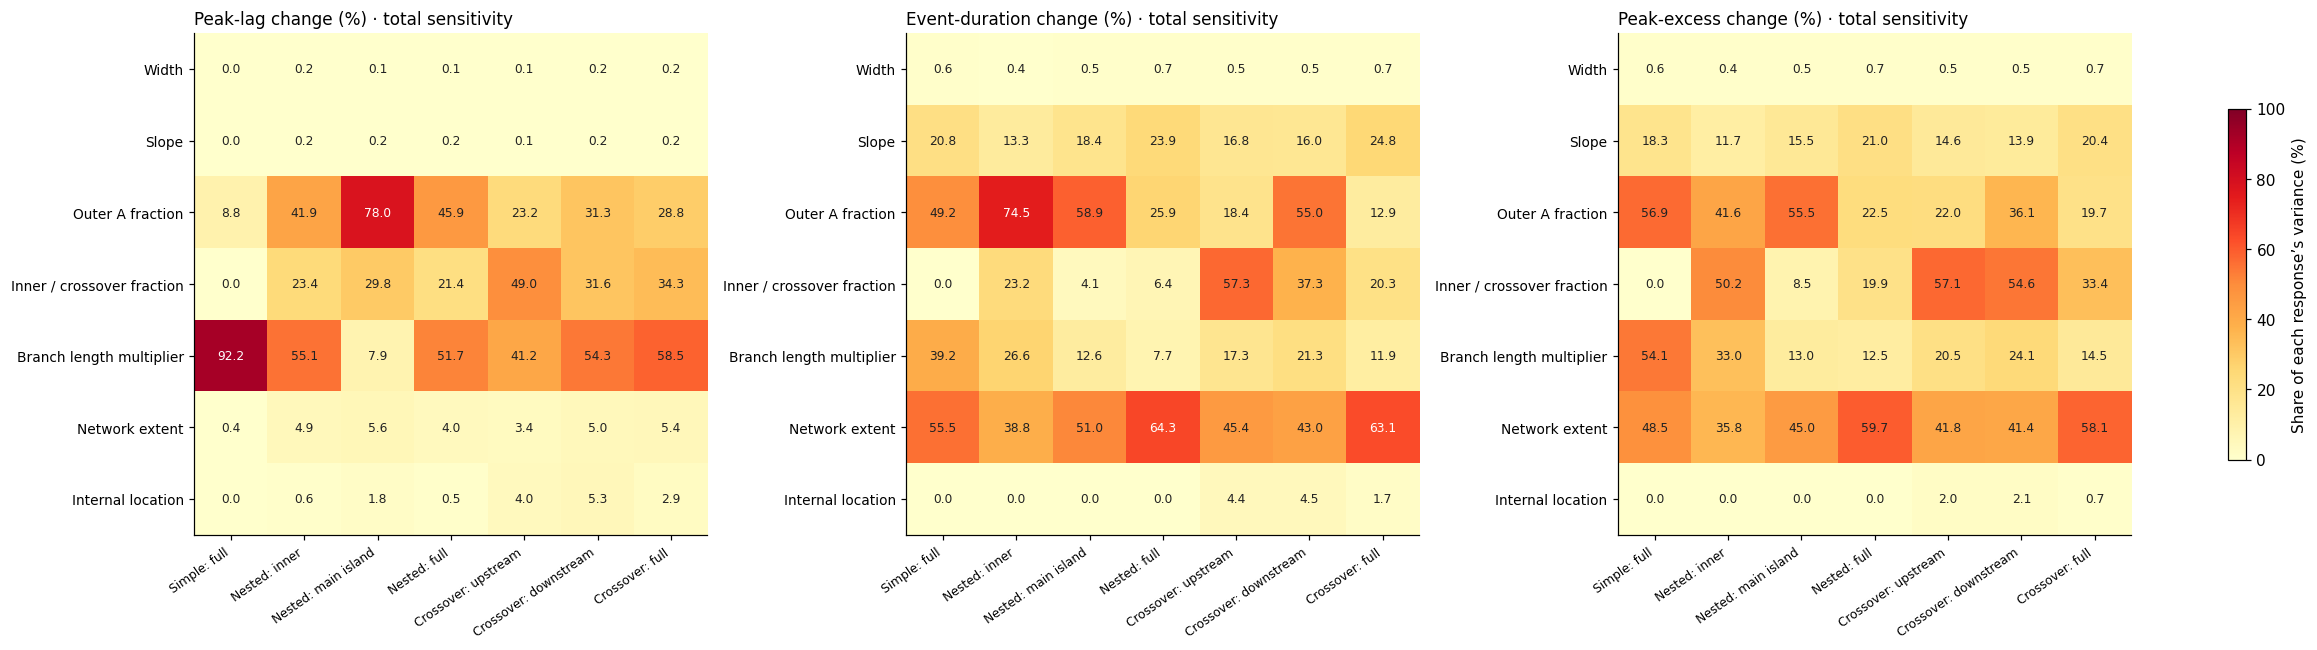

,child_state,response,main_pct,pair_pct,higher_pct
0,crossover/downstream_only,lag_shift_pct,77.61,17.93,4.46
1,crossover/downstream_only,event_duration_change_pct,39.75,44.54,15.71
2,crossover/downstream_only,peak_excess_change_pct,47.58,35.14,17.28
3,crossover/downstream_only,resistance_predictor,91.95,7.92,0.14
4,crossover/full,lag_shift_pct,75.23,20.08,4.70
5,crossover/full,event_duration_change_pct,72.67,20.30,7.03
6,crossover/full,peak_excess_change_pct,65.32,23.87,10.81
7,crossover/full,resistance_predictor,90.66,9.19,0.15
8,crossover/upstream_only,lag_shift_pct,83.19,13.48,3.34
9,crossover/upstream_only,event_duration_change_pct,52.74,36.03,11.23


In [4]:
def heatmap(ax, values, row_labels, col_labels, title, vmax=100):
    image = ax.imshow(values,cmap='YlOrRd',vmin=0,vmax=vmax,aspect='auto')
    ax.set_xticks(range(len(col_labels)),col_labels,rotation=35,ha='right',fontsize=8)
    ax.set_yticks(range(len(row_labels)),row_labels,fontsize=9)
    ax.set_title(title,loc='left',fontsize=11)
    for i,j in np.ndindex(values.shape):
        if np.isfinite(values[i,j]):
            ax.text(j,i,f'{values[i,j]:.1f}',ha='center',va='center',fontsize=8,
                    color='white' if values[i,j]>.6*vmax else '#222222')
    return image

fig,axes=plt.subplots(1,3,figsize=(21,5.8),constrained_layout=True)
for ax,response in zip(axes,ROUTING_RESPONSES):
    matrix=main[main.response.eq(response)].pivot(index='factor',columns='child_state',values='total_share').reindex(index=FACTORS,columns=STATES)*100
    im=heatmap(ax,matrix.to_numpy(),LABELS,NAMES,ROUTING_RESPONSES[response]+' · total sensitivity')
fig.colorbar(im,ax=axes,label='Share of each response’s variance (%)',shrink=.7)
fig.savefig(OUT/'factor_sensitivity.png',dpi=180)
display(fig);plt.close(fig)
# Main effects and higher-order remainders for every response remain in the exports.
display(summary.assign(main_pct=summary.main_share*100,pair_pct=summary.pair_share*100,
    higher_pct=summary.higher_share*100)[['child_state','response','main_pct','pair_pct','higher_pct']].round(2))


## 2. All 21 pair interactions in one overview

Color shows the *additional* variance attributable to each pair, after removing its main effects. A small entry means a weak average pair interaction over the remaining settings; it does not rule out an interaction involving a third factor. Read this alongside the higher-order remainder and total sensitivities above.

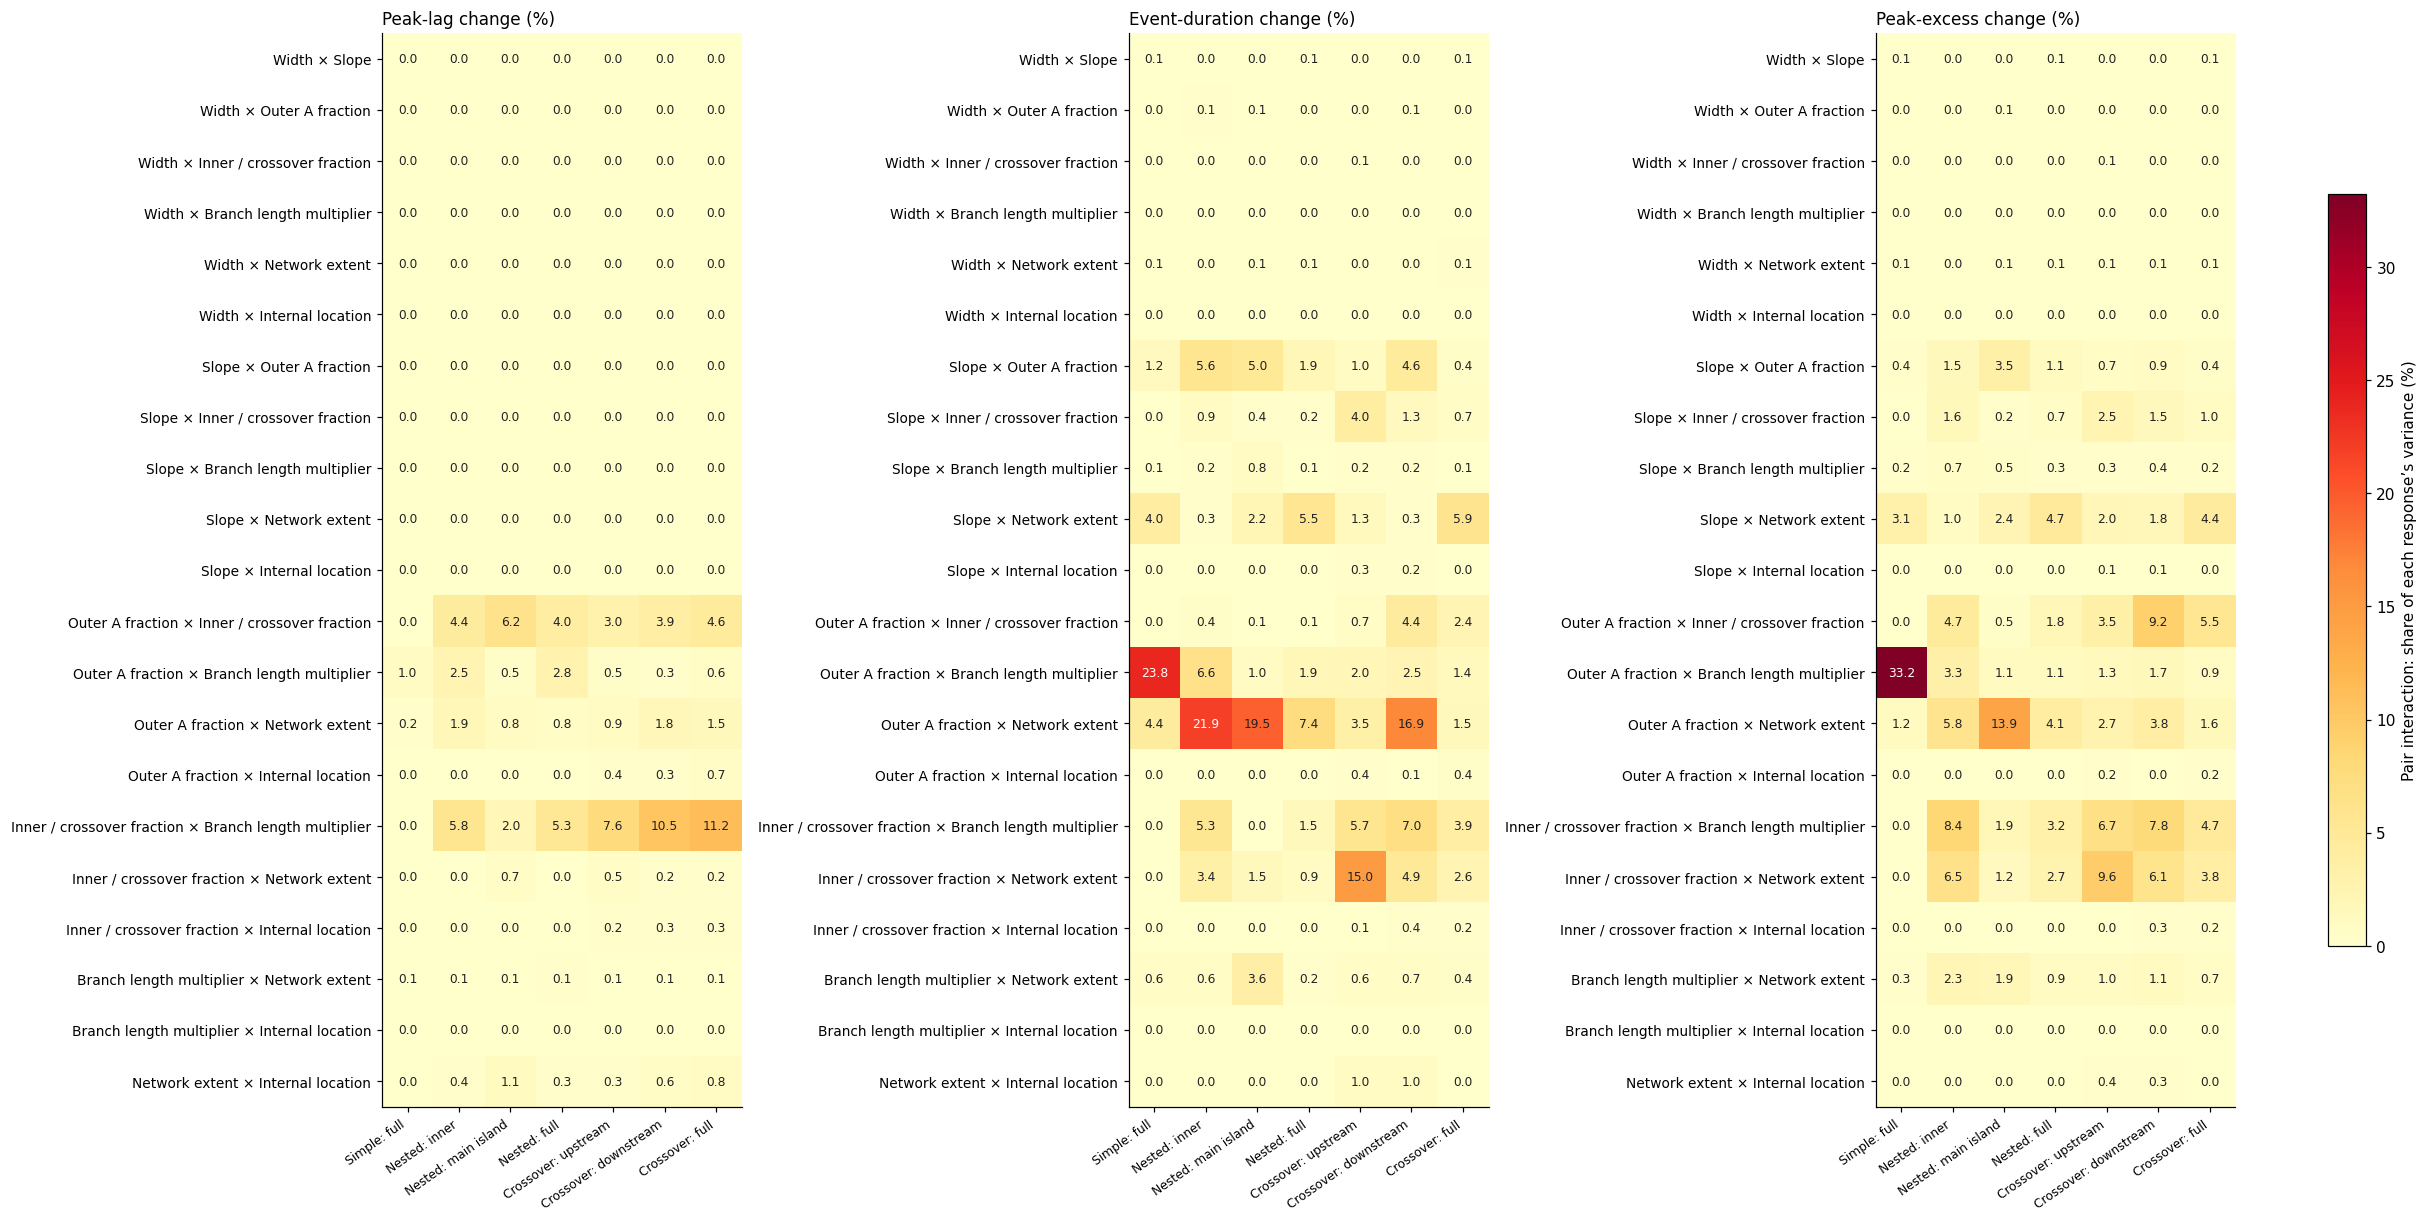

,response,child_state,factor_a,factor_b,variance_pct
558,peak_excess_change_pct,simple/full,outer_a_fraction,length_multiplier,33.21
537,event_duration_change_pct,simple/full,outer_a_fraction,length_multiplier,23.85
370,event_duration_change_pct,nested/inner_only,outer_a_fraction,total_length_m,21.86
454,event_duration_change_pct,nested/main_island_only,outer_a_fraction,total_length_m,19.48
34,event_duration_change_pct,crossover/downstream_only,outer_a_fraction,total_length_m,16.91
475,peak_excess_change_pct,nested/main_island_only,outer_a_fraction,total_length_m,13.93
99,lag_shift_pct,crossover/full,inner_fraction,length_multiplier,11.18
15,lag_shift_pct,crossover/downstream_only,inner_fraction,length_multiplier,10.45
226,peak_excess_change_pct,crossover/upstream_only,inner_fraction,total_length_m,9.63
53,peak_excess_change_pct,crossover/downstream_only,outer_a_fraction,inner_fraction,9.20


In [5]:
pair_labels=[f'{LABEL[a]} × {LABEL[b]}' for a,b in combinations(FACTORS,2)]
selected=pairs[pairs.response.isin(ROUTING_RESPONSES)].copy()
selected['pair_label']=[f'{LABEL[a]} × {LABEL[b]}' for a,b in zip(selected.factor_a,selected.factor_b)]
vmax=max(1,float(selected.pair_share.max()*100))
fig,axes=plt.subplots(1,3,figsize=(22,11),constrained_layout=True)
for ax,response in zip(axes,ROUTING_RESPONSES):
    matrix=selected[selected.response.eq(response)].pivot(index='pair_label',columns='child_state',values='pair_share').reindex(index=pair_labels,columns=STATES)*100
    im=heatmap(ax,matrix.to_numpy(),pair_labels,NAMES,ROUTING_RESPONSES[response],vmax=vmax)
fig.colorbar(im,ax=axes,label='Pair interaction: share of each response’s variance (%)',shrink=.7)
fig.savefig(OUT/'pair_interactions.png',dpi=180)
display(fig);plt.close(fig)
ranked=selected.sort_values('pair_share',ascending=False).copy()
ranked['variance_pct']=ranked.pair_share*100
display(ranked.groupby('response',sort=False).head(4)[['response','child_state','factor_a','factor_b','variance_pct']].round(2))


## 3. Matched changes: direction and dependence on context

For every variable, compare its last and first levels with the other six settings held exactly equal. For location this means downstream minus upstream. These are changes in the **collapse response**, not parent-only changes. For percentage lag shift the units are **percentage points**.

Dots show medians; thick intervals show the 10th–90th percentiles; thin intervals show the full range across the 729 matched contexts. These are deterministic spreads, not confidence intervals. All three levels enter the variance decomposition; the endpoint contrasts below can miss a middle-level extremum.

Matched contrasts are calculated and exported for all three routing responses and the resistance predictor. The detailed interval figure below retains the lag view to limit repetition; use the selected interaction curves for cross-response comparisons.


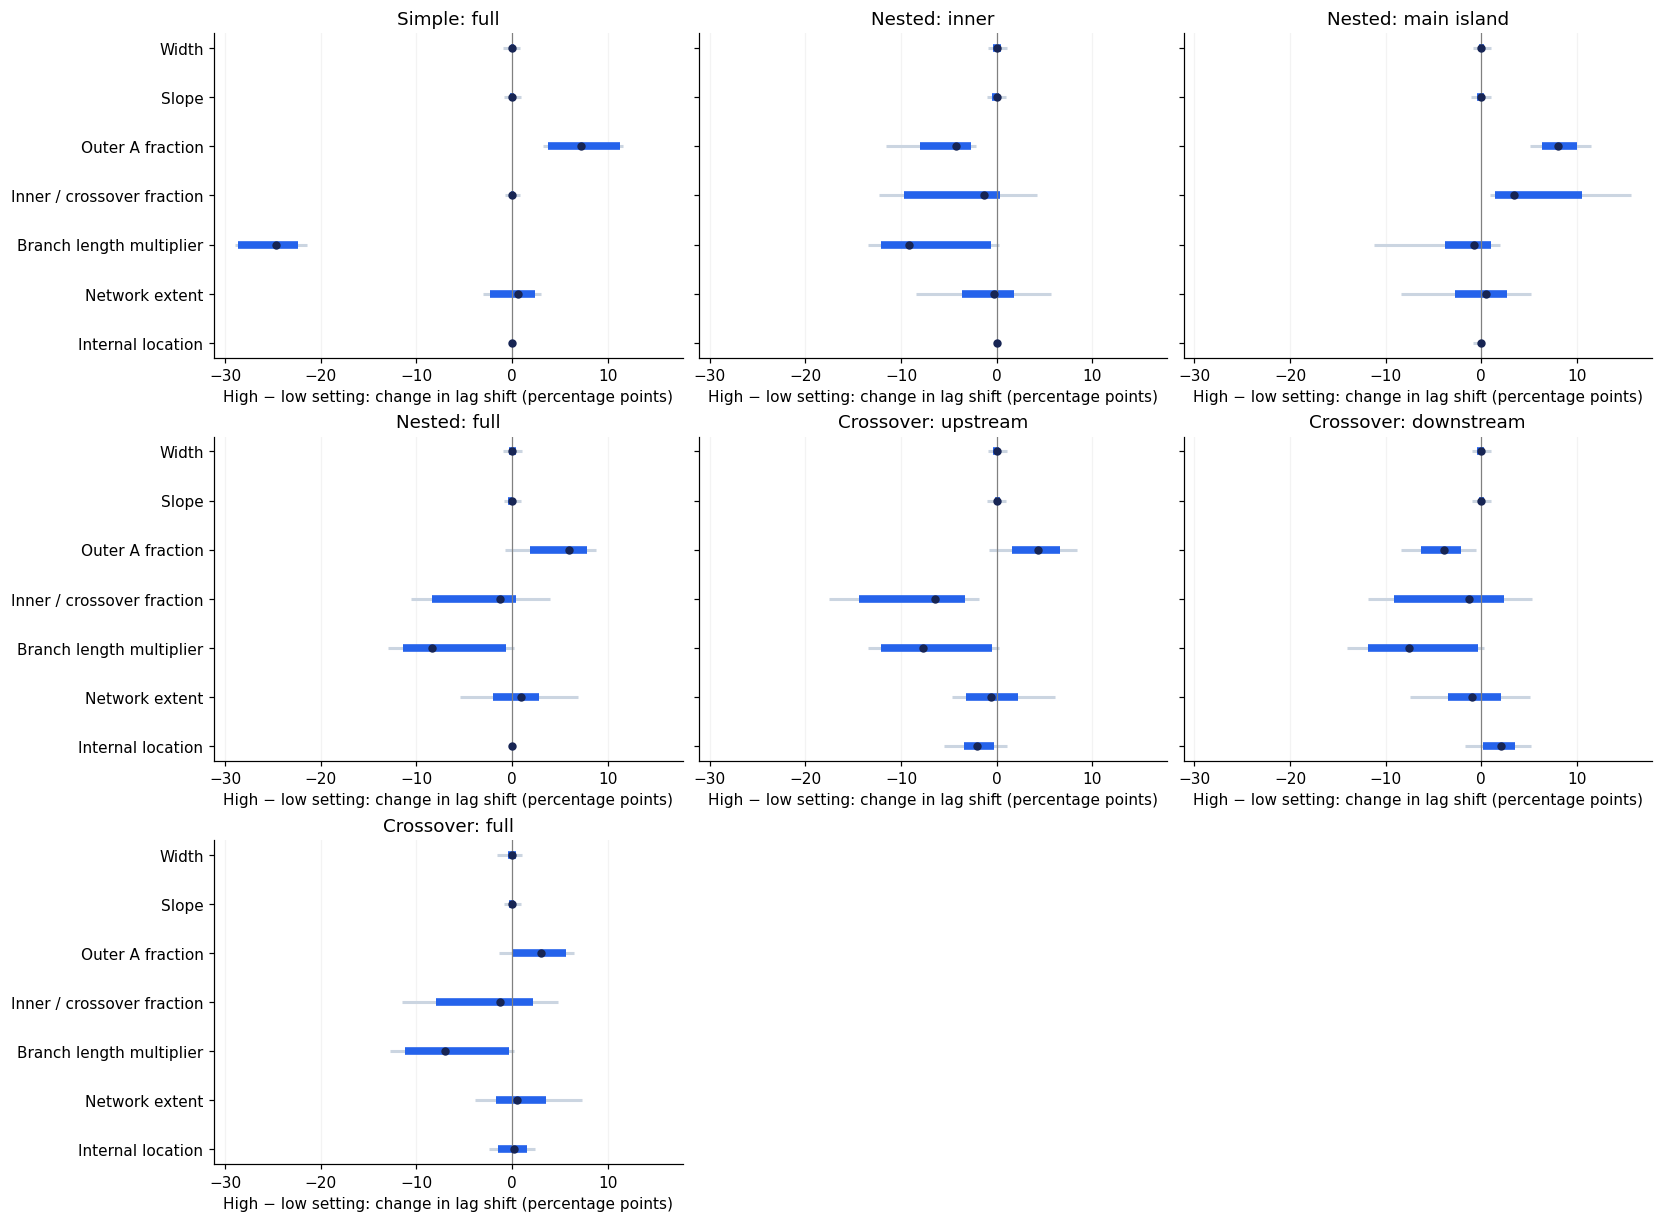

In [6]:
contrast_rows=[]
for state,frame in data.groupby('child_state'):
    for factor in FACTORS:
        others=[f for f in FACTORS if f!=factor]
        for response in RESPONSES:
            table=frame.pivot(index=others,columns=factor,values=response)
            delta=table[LEVELS[factor][-1]]-table[LEVELS[factor][0]]
            contrast_rows.append(dict(child_state=state,factor=factor,response=response,
                low_level=LEVELS[factor][0],high_level=LEVELS[factor][-1],
                minimum=delta.min(),p10=delta.quantile(.1),median=delta.median(),
                p90=delta.quantile(.9),maximum=delta.max(),mean_absolute_change=delta.abs().mean(),
                n_contexts=len(delta)))
contrasts=pd.DataFrame(contrast_rows)
fig,axes=plt.subplots(3,3,figsize=(15,11),constrained_layout=True,sharex=True,sharey=True)
for ax,state in zip(axes.flat,STATES):
    c=contrasts[(contrasts.child_state==state)&(contrasts.response=='lag_shift_pct')].set_index('factor').reindex(FACTORS)
    y=np.arange(7)
    ax.hlines(y,c.minimum,c.maximum,color='#cbd5e1',lw=2)
    ax.hlines(y,c.p10,c.p90,color='#2563eb',lw=5)
    ax.scatter(c['median'],y,color='#172554',s=20,zorder=3)
    ax.axvline(0,color='gray',lw=.8);ax.set_yticks(y,LABELS)
    ax.set(title=NAME[state],xlabel='High − low setting: change in lag shift (percentage points)')
    ax.grid(axis='x',alpha=.15)
for ax in list(axes.flat)[len(STATES):]: ax.set_visible(False)
for ax in list(axes.flat)[:len(STATES)]: ax.tick_params(axis='x', labelbottom=True)
axes[0,0].invert_yaxis()
fig.savefig(OUT/'matched_changes.png',dpi=180)
display(fig);plt.close(fig)


## 4. Does the full primary x-variable have the same sensitivities?

The predictor analysed here is **the same x-variable used in the primary RAPID and synthetic resistance–timing plots**:

$$X=L_f E[-\log_{10}(\Lambda_K)],\qquad \Lambda_K=K_{after}/K_{before}.$$

- **Length fraction $L_f$:** sum of parent channel lengths in the matched comparison domain divided by the sum across the entire parent network. Each channel is counted once; this is not simply the domain's downstream span divided by network extent.
- **Exposure $E$:** fraction of inlet flow reaching the domain's upstream boundary, propagated using the parent's width-allocation rule. It equals outer A fraction for nested inner collapse and one for the enclosing outer-domain comparisons, including main-island collapse.
- **Resistance change:** $-\log_{10}(\Lambda_K)$, positive when equivalent hydraulic resistance decreases. Hydraulic resistance $K$ is distinct from the routing time parameter.

The saved column is `resistance_predictor`; `width_fraction` stores exposure. The loading cell verifies the complete formula against every result. These weighting factors were already included in the preceding version of this notebook.

Compare total sensitivity of percentage lag change with total sensitivity of this full predictor. These panels are **not a predictive fit**: matching patterns do not establish predictive accuracy, and mismatches identify mechanisms to investigate. Each panel is normalized by its own response variance.

The weighting factors do not introduce absolute scale: uniform network-length scaling cancels in $L_f$ and in the resistance ratio; uniform width scaling cancels in the resistance ratio and width-derived exposure. Absolute slope is absent from this geometry-only predictor. Local length changes can still alter both $L_f$ and the resistance ratio. Therefore zero sensitivity to absolute width, slope or extent can remain even with both weights included.

The sensitivity comparison now includes all three routing responses and the predictor. The following scatter plots use the same x-variable for each response, without assuming equal predictive power.


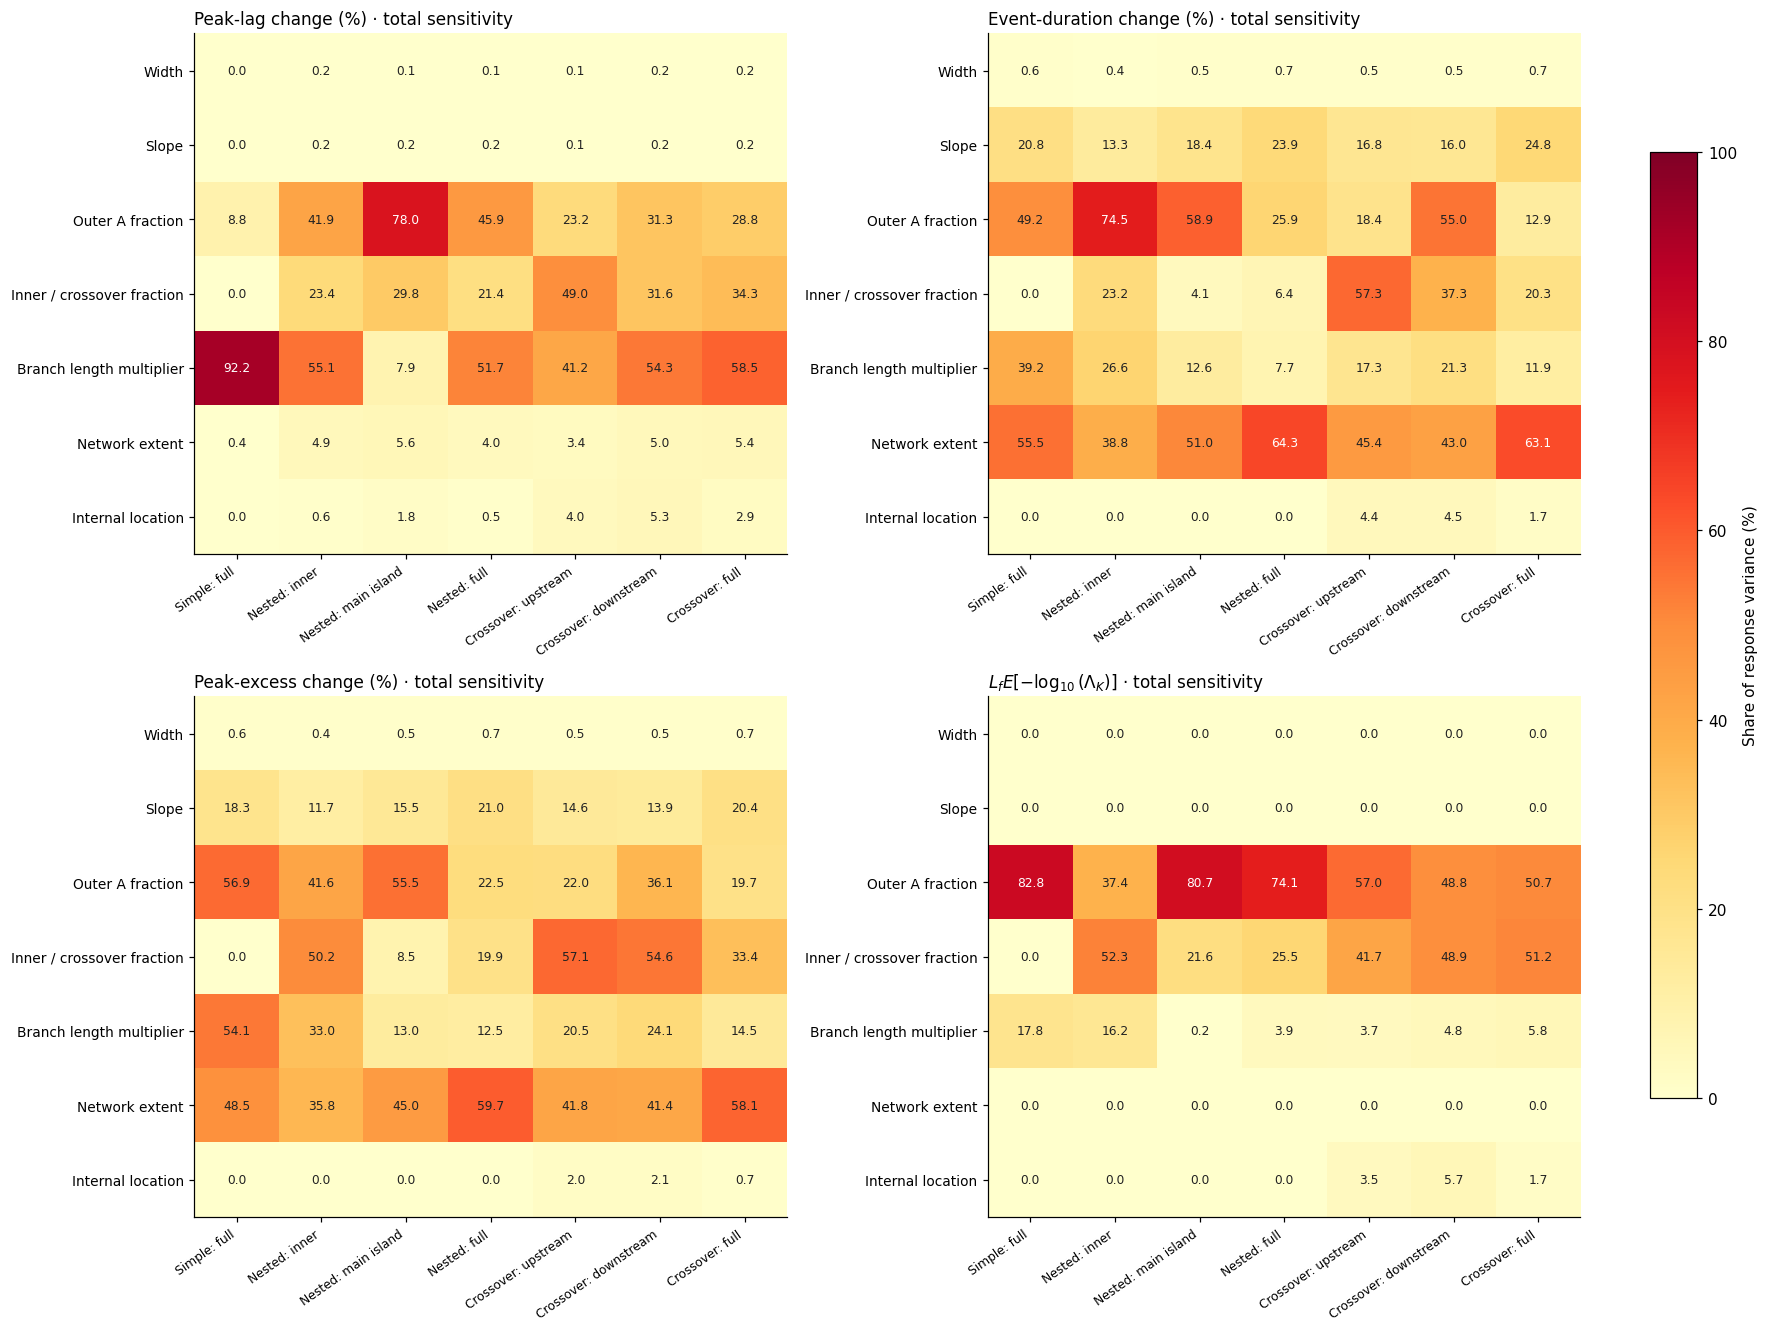

,,response,event_duration_change_pct,lag_shift_pct,peak_excess_change_pct,resistance_predictor,lag_pct_minus_predictor_pp
child_state,factor_a,factor_b,,,,,
crossover/full,inner_fraction,length_multiplier,3.89,11.18,4.67,1.18,10.00
crossover/downstream_only,inner_fraction,length_multiplier,6.99,10.45,7.80,1.12,9.33
crossover/upstream_only,inner_fraction,length_multiplier,5.66,7.60,6.72,1.00,6.60
nested/full,inner_fraction,length_multiplier,1.50,5.30,3.21,0.88,4.43
nested/main_island_only,outer_a_fraction,inner_fraction,0.07,6.15,0.46,2.39,3.77
nested/inner_only,inner_fraction,length_multiplier,5.33,5.78,8.39,2.48,3.30
nested/full,outer_a_fraction,length_multiplier,1.92,2.82,1.14,0.12,2.70
crossover/downstream_only,outer_a_fraction,inner_fraction,4.42,3.88,9.20,5.97,-2.08
nested/main_island_only,inner_fraction,length_multiplier,0.02,2.04,1.90,0.03,2.02


In [7]:
fig,axes=plt.subplots(2,2,figsize=(16,12),constrained_layout=True)
for ax,response in zip(axes.flat,RESPONSES):
    matrix=main[main.response.eq(response)].pivot(index='factor',columns='child_state',values='total_share').reindex(index=FACTORS,columns=STATES)*100
    im=heatmap(ax,matrix.to_numpy(),LABELS,NAMES,RESPONSES[response]+' · total sensitivity')
fig.colorbar(im,ax=axes,label='Share of response variance (%)',shrink=.8)
fig.savefig(OUT/'resistance_sensitivity_comparison.png',dpi=180)
display(fig);plt.close(fig)
# All 21 pairs are also compared in the exported table, without another interaction figure.
resistance_pairs=pairs.pivot(index=['child_state','factor_a','factor_b'],columns='response',values='pair_share').mul(100)
resistance_pairs['lag_pct_minus_predictor_pp']=resistance_pairs.lag_shift_pct-resistance_pairs.resistance_predictor
display(resistance_pairs.reindex(resistance_pairs.lag_pct_minus_predictor_pp.abs().sort_values(ascending=False).index).head(10).round(2))


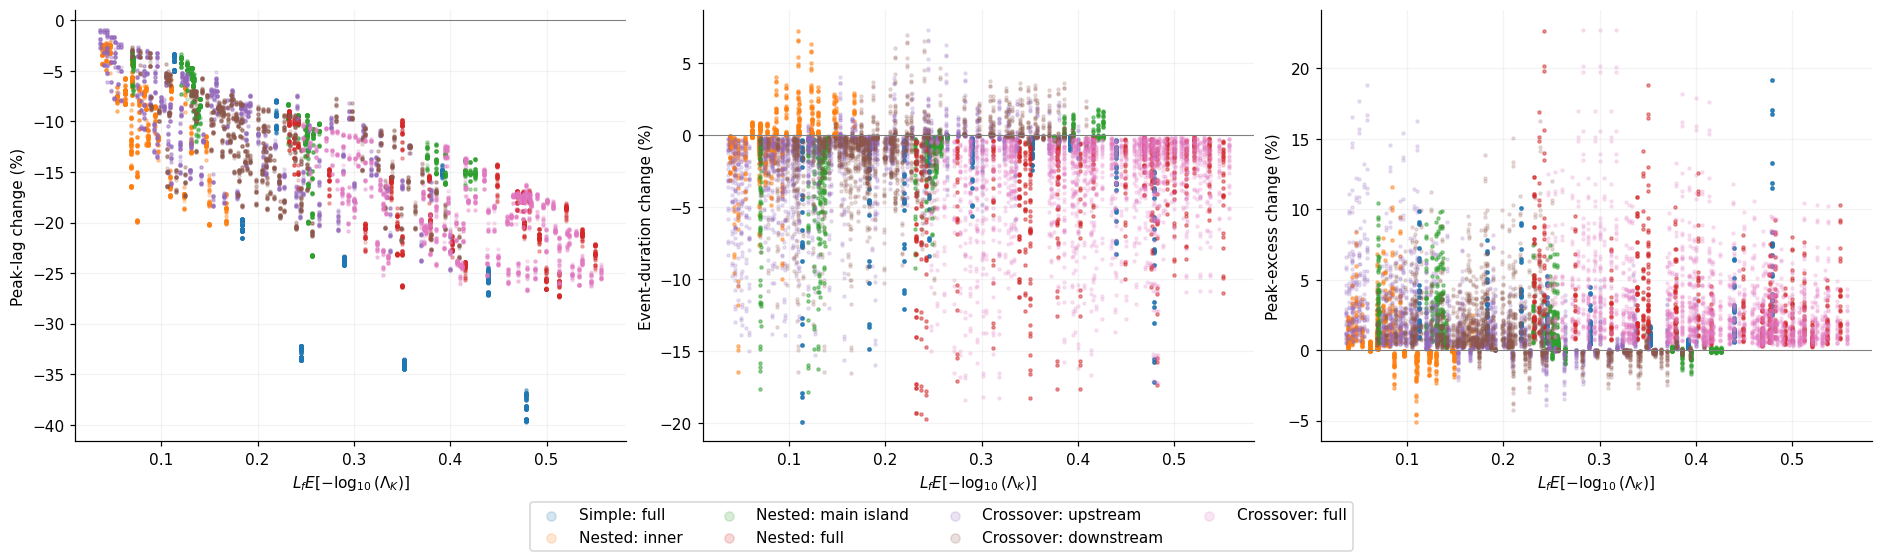

,parent_multiple,child_multiple
child_state,,
crossover/downstream_only,0,0
crossover/full,0,0
crossover/upstream_only,0,0
nested/full,0,0
nested/inner_only,0,0
nested/main_island_only,0,0
simple/full,0,0


In [8]:
fig,axes=plt.subplots(1,3,figsize=(17,5),constrained_layout=True)
for ax,response in zip(axes,ROUTING_RESPONSES):
    for state in STATES:
        frame=data[data.child_state.eq(state)]
        ax.scatter(frame.resistance_predictor,frame[response],s=4,alpha=.18,label=NAME[state],rasterized=True)
    ax.set(xlabel=r'$L_f E[-\log_{10}(\Lambda_K)]$',ylabel=ROUTING_RESPONSES[response])
    ax.axhline(0,color='gray',lw=.7);ax.grid(alpha=.15)
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='outside lower center',ncol=4,markerscale=3)
fig.savefig(OUT/'resistance_three_responses.png',dpi=180)
display(fig);plt.close(fig)
# Counts are annotations only; they do not enter the variance decomposition.
display(data.assign(parent_multiple=data.parent_screened_peak_count.gt(1),
                    child_multiple=data.child_screened_peak_count.gt(1)).groupby('child_state').agg(
    parent_multiple=('parent_multiple','sum'),child_multiple=('child_multiple','sum')))


## 5. Selected interactions, explained across all three responses

For each routing response, take its highest-variance pair interaction across
collapse types. Plot that same state/factor combination for **all three responses**
in one row. This selects detailed examples from the full balanced analysis rather
than repeating every possible plot. Curves average over the remaining five factors;
parallel curves indicate little average interaction. Selection is descriptive,
not a significance test.


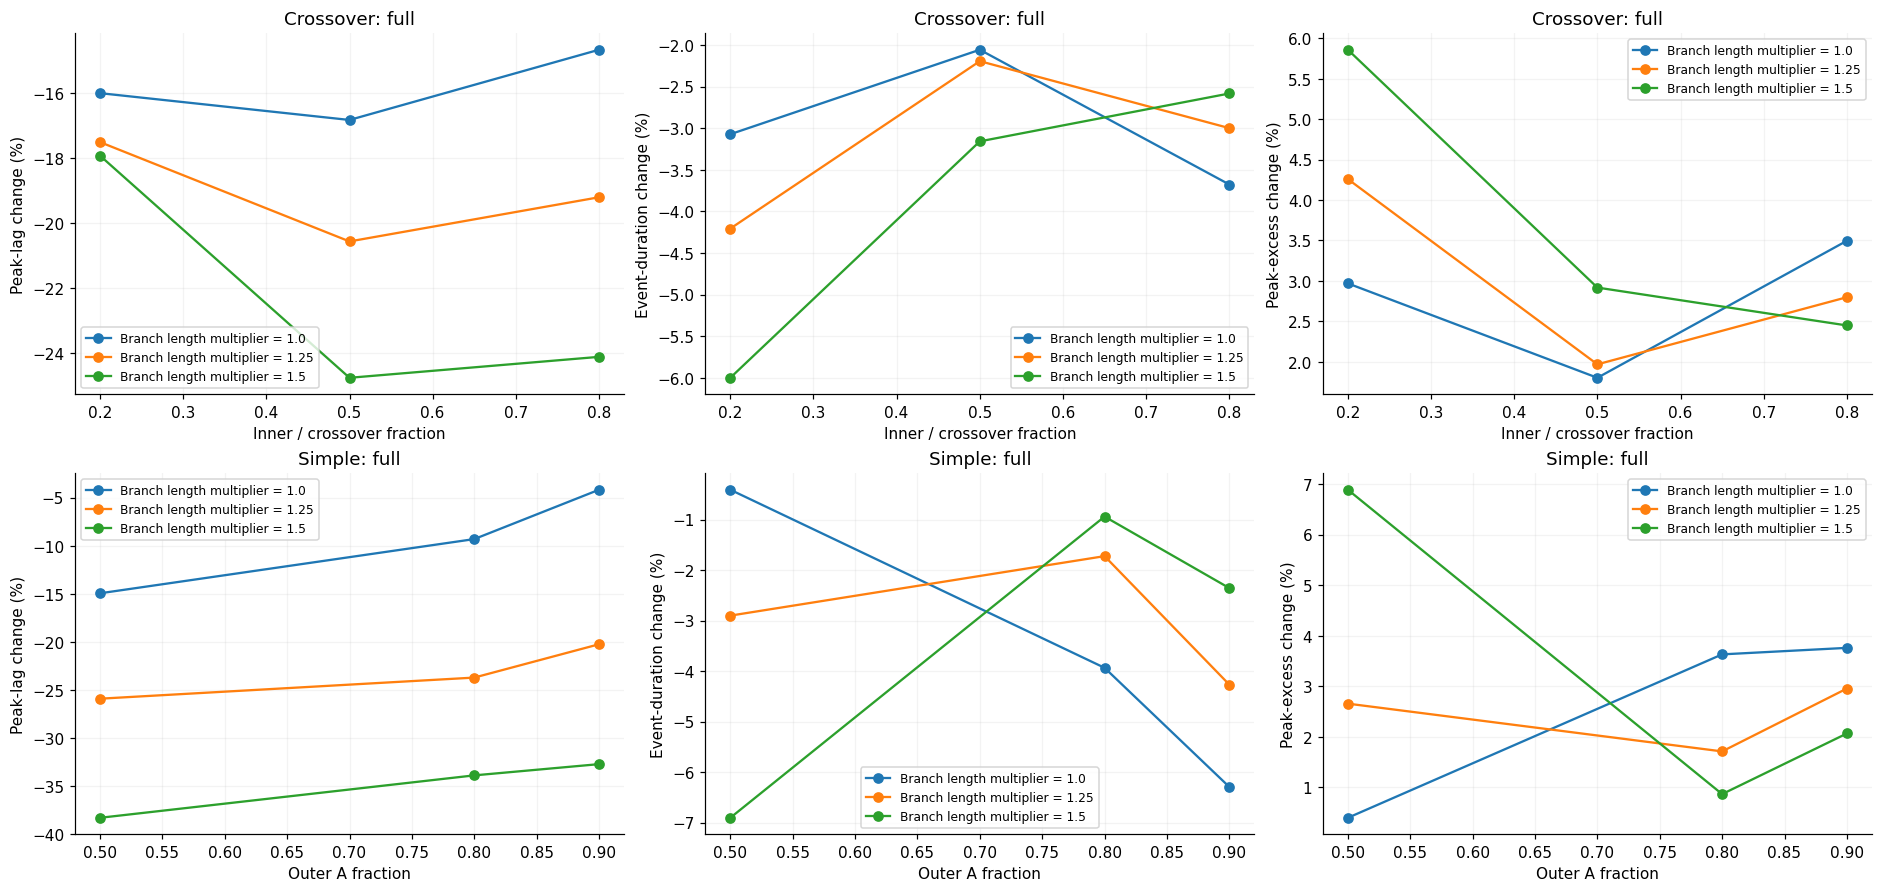

In [9]:
chosen=[]
for response in ROUTING_RESPONSES:
    top=pairs[pairs.response.eq(response)].sort_values('pair_share',ascending=False).iloc[0]
    key=(top.child_state,top.factor_a,top.factor_b)
    if key not in chosen: chosen.append(key)
fig,axes=plt.subplots(len(chosen),3,figsize=(17,4*len(chosen)),constrained_layout=True,squeeze=False)
for row,(state,factor,condition) in enumerate(chosen):
    frame=data[data.child_state.eq(state)]
    for col,response in enumerate(ROUTING_RESPONSES):
        ax=axes[row,col]
        means=frame.groupby([factor,condition])[response].mean().unstack().reindex(LEVELS[factor])
        for value in LEVELS[condition]:
            ax.plot(means.index,means[value],'o-',label=f'{LABEL[condition]} = {value}')
        if factor in ['reference_slope','total_width_m','total_length_m']:ax.set_xscale('log')
        ax.set(title=NAME[state],xlabel=LABEL[factor],ylabel=ROUTING_RESPONSES[response])
        ax.grid(alpha=.15);ax.legend(fontsize=8)
fig.savefig(OUT/'selected_marginal_interactions.png',dpi=180)
display(fig);plt.close(fig)


## Numerical context and next investigations

Keep all grid points in this balanced decomposition. Removing capped runs or small lag shifts would change the experimental distribution and invalidate the simple orthogonal formulas. Flag them here; investigate important effects with matched reruns or a separately designed balanced subset later. The effects measured here include any contribution from configuration-dependent timesteps and celerity caps.

Use the overview to choose follow-ups:

- Large main and small interaction effects: summarize a consistent directional response.
- Large total but small main effects: explain the combinations that control the response.
- Large higher-order remainder: pair plots alone are insufficient; inspect a third conditioning factor.
- Lag sensitivity absent from the resistance predictor: examine travel-time scaling, flow partition, peak mixing and numerical regularization.

Do not call a variable unimportant from one baseline slice or from a small signed average. Check total sensitivity, absolute matched changes, and percentage lag responses.

Event durationing and peak attenuation are distinct. A narrow delayed branch can increase spread without moving the largest peak. Discontinuous peak timing can also reflect a switch in which peak is highest. Event duration and threshold-based peak counts are supporting diagnostics; neither replaces the full-volume spread.


In [10]:
qa=data.assign(any_cap=data.parent_capped_segments.gt(0)|data.child_capped_segments.gt(0),
    within_one_dt=data.lag_shift_seconds.abs().le(data.timing_resolution_seconds))
display(qa.groupby('child_state').agg(comparisons=('configuration_id','size'),
    any_cap=('any_cap','sum'),within_one_dt=('within_one_dt','sum')))
for name,frame in [('main_total_effects',main),('pair_interactions',pairs),('variance_partition',summary),
                   ('matched_contrasts',contrasts),('event_shape_comparisons',data),('resistance_pair_comparison',resistance_pairs.reset_index())]:
    frame.to_csv(OUT/f'{name}.csv',index=False)
(OUT/'provenance.json').write_text(json.dumps(dict(plan_id=manifest['plan_id'],source=manifest['source'],
    weighting='equal weight per complete factorial configuration, separately by collapse type',
    factors=FACTORS,responses=RESPONSES,method='discrete functional variance decomposition',
    primary_predictor='length_fraction * width_fraction * (-log10(Lambda_matched))',
    contrasts='last minus first level, matched on all other factors',
    event_shape_cache=json.loads((OUT/'event_shape_cache.json').read_text())),indent=2))
print('Analysis saved to',OUT.relative_to(ROOT))


Analysis saved to synthetic_experiments/outputs/hydraulic_alpha065_20260930/full_grid_island/factor_analysis


,comparisons,any_cap,within_one_dt
child_state,,,
crossover/downstream_only,2187,0,0
crossover/full,2187,0,0
crossover/upstream_only,2187,0,0
nested/full,2187,0,0
nested/inner_only,2187,0,0
nested/main_island_only,2187,0,0
simple/full,2187,0,0


## New island treatment: compare the three nested children

All three use the same original parent in each configuration. The main-island treatment preserves the lengthened upper inner branch, while inner and full topological collapse remove it. Their different sensitivities can therefore reflect which geometry survives as well as how much resistance changes. The table below gives the distribution of each response over the complete grid; the sensitivity figures above retain the conditioning information.

In [11]:
nested=data.loc[data.child_state.isin(['nested/inner_only','nested/main_island_only','nested/full'])]
display(nested.groupby('child_state').agg(comparisons=('configuration_id','size'),
    min_lag_pct=('lag_shift_pct','min'),median_lag_pct=('lag_shift_pct','median'),
    max_lag_pct=('lag_shift_pct','max'),median_weighted_predictor=('resistance_predictor','median')))
island_effects=main.loc[(main.child_state=='nested/main_island_only') & (main.response=='lag_shift_pct'),
    ['factor','main_share','total_share']].set_index('factor').mul(100).sort_values('total_share',ascending=False)
display(island_effects.rename(columns={'main_share':'Main effect (%)','total_share':'Total sensitivity (%)'}).round(2))
display(nested.groupby('child_state')[['temporal_spread_change_pct','peak_excess_change_pct','event_duration_change_pct']].agg(['min','median','max']).round(2))


,comparisons,min_lag_pct,median_lag_pct,max_lag_pct,median_weighted_predictor
child_state,,,,,
nested/full,2187,-27.325581,-18.103448,-8.958838,0.401860
nested/inner_only,2187,-20.231214,-8.256881,-2.162162,0.077280
nested/main_island_only,2187,-23.333333,-10.000000,-2.905569,0.241699


,Main effect (%),Total sensitivity (%)
factor,,
outer_a_fraction,65.16,78.00
inner_fraction,15.72,29.76
length_multiplier,1.51,7.91
total_length_m,0.01,5.60
internal_location,0.57,1.79
reference_slope,0.00,0.16
total_width_m,0.00,0.14


temporal_spread_change_pct               \
                                               min median   max   
child_state                                                       
nested/full                                 -12.42  -0.55 -0.02   
nested/inner_only                            -7.14   0.01  3.88   
nested/main_island_only                      -8.46  -0.21  1.27   

                        peak_excess_change_pct                \
                                           min median    max   
child_state                                                    
nested/full                               0.26   2.27  22.64   
nested/inner_only                        -5.06   0.38  11.60   
nested/main_island_only                  -1.69   1.00  10.44   

                        event_duration_change_pct               
                                              min median   max  
child_state                                                     
nested/full                                -19.74  -2.14 -0.13  
nested/inner_only                          -16.46  -0.13  7.23  
nested/main_island_only                    -17.82  -0.78  1.84

## Focused width–length hydrographs

These examples are rerouted under the selected settings. They show equal-width lengthening, narrow-branch lengthening, and same-topology shortening. A separated second peak is not assumed to persist after the hydraulic revision. The supplementary table reports temporal spread and volume-quantile duration; these do not replace the three primary responses above.

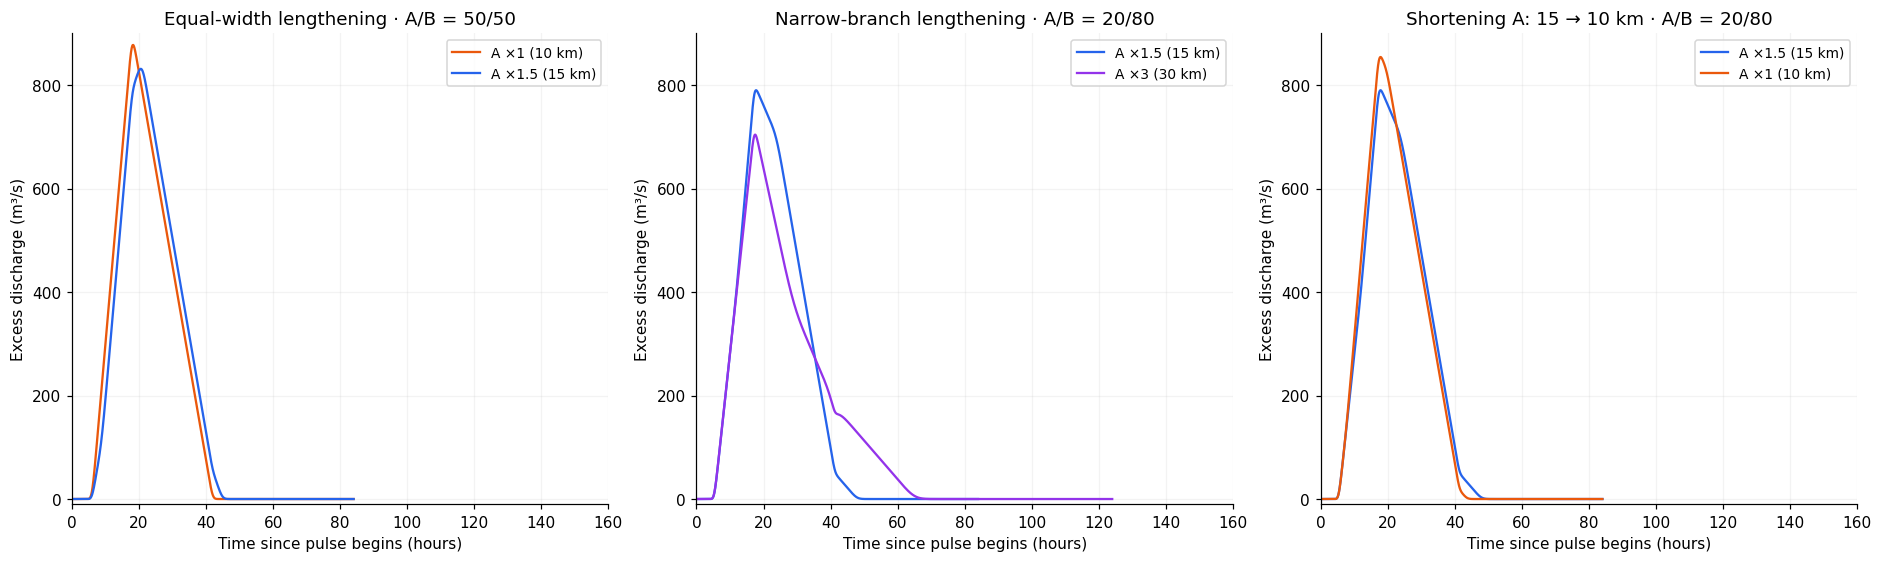

,example,outer_a_fraction,length_multiplier,peak_lag_hours,spread_hours,peak_excess_cms,duration_t01_t99_hours
0,Equal-width lengthening · A/B = 50/50,0.5,1.0,6.20,7.50,877.56,31.10
1,Equal-width lengthening · A/B = 50/50,0.5,1.5,8.50,7.65,831.34,32.11
2,Narrow-branch lengthening · A/B = 20/80,0.2,1.5,5.80,7.96,790.01,33.85
3,Narrow-branch lengthening · A/B = 20/80,0.2,3.0,5.53,12.14,704.17,51.24
4,Shortening A: 15 → 10 km · A/B = 20/80,0.2,1.5,5.80,7.96,790.01,33.85
5,Shortening A: 15 → 10 km · A/B = 20/80,0.2,1.0,5.78,7.56,854.24,31.46


In [12]:
FOCUSED=ACTIVE_RUN.parent/'side_channel_width_length'
examples=[(.5,[1.,1.5],'Equal-width lengthening · A/B = 50/50'),
          (.2,[1.5,3.],'Narrow-branch lengthening · A/B = 20/80'),
          (.2,[1.5,1.],'Shortening A: 15 → 10 km · A/B = 20/80')]
required=[FOCUSED/f'a{a:g}_m{m:g}_hydrograph.parquet' for a,ms,_ in examples for m in ms]
if all(p.exists() for p in required):
    fig,axes=plt.subplots(1,3,figsize=(17,5),constrained_layout=True)
    colors={1.:'#ea580c',1.5:'#2563eb',3.:'#9333ea'}
    illustration_rows=[]
    for ax,(a,ms,title) in zip(axes,examples):
        for m in ms:
            key=f'a{a:g}_m{m:g}'
            h=pd.read_parquet(FOCUSED/f'{key}_hydrograph.parquet')
            mt=json.loads((FOCUSED/f'{key}_metrics.json').read_text())
            assert mt['n_celerity_capped']==0
            t=h.time_seconds.to_numpy()-mt['buffer_hours']*3600
            q=h.outlet_cms.to_numpy()-100
            event=t>=-1e-6
            shape=volume_shape(t[event],q[event],mt['dt_seconds'])
            ax.plot(t/3600,q,color=colors[m],label=f'A ×{m:g} ({10*m:g} km)')
            illustration_rows.append(dict(example=title,outer_a_fraction=a,length_multiplier=m,
                peak_lag_hours=mt['peak_lag_seconds']/3600,
                spread_hours=shape['temporal_sd_seconds']/3600,
                peak_excess_cms=q[event].max(),duration_t01_t99_hours=shape['duration_t01_t99_seconds']/3600))
        ax.set(xlim=(0,160),ylim=(-10,900),title=title,xlabel='Time since pulse begins (hours)',ylabel='Excess discharge (m³/s)')
        ax.grid(alpha=.15);ax.legend(fontsize=9)
    fig.savefig(OUT/'focused_shape_examples.png',dpi=180)
    display(fig);plt.close(fig)
    illustrations=pd.DataFrame(illustration_rows)
    illustrations.to_csv(OUT/'focused_shape_examples.csv',index=False)
    display(illustrations.round(2))
else:
    display(Markdown('Focused illustrations unavailable. Run `investigations/selected_hydraulic_report.py` after the selected extension; the factorial analysis above is complete without these files.'))


## Reading the selected result

The three primary responses describe timing, event duration and peak excess. Their sensitivities depend on grid ranges, forcing, allocation and routing assumptions. Read the recomputed variance shares alongside signed matched contrasts. The focused hydrographs above use the same selected hydraulic setup.

## Current predictor benchmark

Continue with [synthetic_predictor_validation.ipynb](synthetic_predictor_validation.ipynb), which uses the selected results and the original geometry-group validation splits. Earlier geometry-screen notebooks are labeled historical.